In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

     -------------------------------------- 258.3/258.3 kB 3.2 MB/s eta 0:00:00
     -------------------------------------- 309.1/309.1 kB 3.2 MB/s eta 0:00:00
  Attempting uninstall: joblib
    Found existing installation: joblib 1.1.0
    Uninstalling joblib-1.1.0:
      Successfully uninstalled joblib-1.1.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Dataset for Data Analytics - Sheet1.csv')

In [3]:
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1200, 14)


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [4]:
df.info()
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       891 non-null    object 
 12  ReferralSource   1200 non-null   object 
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), object(10)
memory usage: 131.4+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
OrderID,1200,1200,ORD200000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,1200,671,2023-08-20,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerID,1200,1189,C38840,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1200,7,Printer,181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1200.0,NaN,NaN,NaN,2.945833,1.407557,1.0,2.0,3.0,4.0,5.0
UnitPrice,1200.0,NaN,NaN,NaN,356.41275,197.177146,11.39,186.0625,364.21,521.57,699.93
ShippingAddress,1200,655,533 Main St,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaymentMethod,1200,5,Online,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrderStatus,1200,5,Cancelled,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TrackingNumber,1200,1200,TRK37947903,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64


In [6]:
display(df.isnull().sum())

OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Quantity,1200.0,2.945833,1.407557,1.00,2.0000,3.000,4.000,5.00
UnitPrice,1200.0,356.412750,197.177146,11.39,186.0625,364.210,521.570,699.93
ItemsInCart,1200.0,5.485000,2.281983,1.00,4.0000,5.000,7.000,10.00
TotalPrice,1200.0,1053.968300,819.856558,11.39,410.5200,823.615,1578.475,3456.40


In [9]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [10]:
# Missing coupon means no coupon was recorded.
# Confirm this assumption if your dataset documentation is unclear.
df["CouponCode"] = df["CouponCode"].fillna("No Coupon")

In [11]:
df["IsWeekend"] = (df["Date"].dt.dayofweek >= 5).astype(int)

In [12]:
df["OrderMonth"] = df["Date"].dt.month

In [13]:
customer_features = df.groupby("CustomerID").agg(
    TotalSpend=("TotalPrice", "sum"),
    TotalQuantity=("Quantity", "sum"),
    OrderCount=("OrderID", "nunique"),
    AverageOrderValue=("TotalPrice", "mean"),
    AverageItemsInCart=("ItemsInCart", "mean"),
    AverageUnitPrice=("UnitPrice", "mean"),
    UniqueProducts=("Product", "nunique"),
    WeekendOrderRate=("IsWeekend", "mean")
).reset_index()

In [14]:
display(customer_features.head())

,CustomerID,TotalSpend,TotalQuantity,OrderCount,AverageOrderValue,AverageItemsInCart,AverageUnitPrice,UniqueProducts,WeekendOrderRate
0,C10002,1470.03,3,1,1470.03,4.0,490.01,1,0.0
1,C10054,153.48,2,1,153.48,7.0,76.74,1,0.0
2,C10126,1349.80,2,1,1349.80,4.0,674.90,1,1.0
3,C10154,1303.04,4,1,1303.04,8.0,325.76,1,0.0
4,C10211,635.90,5,1,635.90,10.0,127.18,1,0.0


In [15]:
print("Customer profiles:", customer_features.shape)

Customer profiles: (1189, 9)


In [16]:
categorical_cols = [
    "Product",
    "PaymentMethod",
    "OrderStatus",
    "ReferralSource",
    "CouponCode"
]

In [17]:
encoded = pd.get_dummies(
    df[categorical_cols],
    dtype=int
)

In [18]:
encoded["CustomerID"] = df["CustomerID"]

In [19]:
encoded_features = encoded.groupby("CustomerID").mean().reset_index()

In [20]:
customer_features = customer_features.merge(
    encoded_features,
    on="CustomerID",
    how="left"
)

In [21]:
print("Final customer feature shape:", customer_features.shape)

Final customer feature shape: (1189, 35)


In [22]:
display(customer_features.head())

,CustomerID,TotalSpend,TotalQuantity,OrderCount,AverageOrderValue,AverageItemsInCart,AverageUnitPrice,UniqueProducts,WeekendOrderRate,Product_Chair,...,OrderStatus_Shipped,ReferralSource_Email,ReferralSource_Facebook,ReferralSource_Google,ReferralSource_Instagram,ReferralSource_Referral,CouponCode_FREESHIP,CouponCode_No Coupon,CouponCode_SAVE10,CouponCode_WINTER15
0,C10002,1470.03,3,1,1470.03,4.0,490.01,1,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,C10054,153.48,2,1,153.48,7.0,76.74,1,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,C10126,1349.80,2,1,1349.80,4.0,674.90,1,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,C10154,1303.04,4,1,1303.04,8.0,325.76,1,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,C10211,635.90,5,1,635.90,10.0,127.18,1,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [23]:
customer_ids = customer_features["CustomerID"]

In [24]:
X = customer_features.drop(columns=["CustomerID"])

In [25]:
print("Feature matrix shape:", X.shape)

Feature matrix shape: (1189, 34)


In [26]:
print("Missing values:", X.isnull().sum().sum())

Missing values: 0


In [27]:
from sklearn.impute import SimpleImputer

In [28]:
imputer = SimpleImputer(strategy="median")

In [29]:
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

In [30]:
from sklearn.preprocessing import StandardScaler

In [31]:
scaler = StandardScaler()

In [32]:
X_scaled = scaler.fit_transform(X_imputed)

In [33]:
print("Scaled matrix shape:", X_scaled.shape)

Scaled matrix shape: (1189, 34)


In [34]:
print("Mean of first five features:", X_scaled.mean(axis=0)[:5])

Mean of first five features: [ 9.56155069e-17 -1.79279075e-17 -6.79019498e-16  1.91231014e-16
  1.19519384e-16]


In [35]:
print("Standard deviation of first five features:", X_scaled.std(axis=0)[:5])

Standard deviation of first five features: [1. 1. 1. 1. 1.]


In [36]:
from sklearn.decomposition import PCA

In [37]:
# Fit PCA to examine the variance explained by all components
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

In [38]:
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

In [39]:
print("Variance explained by each component:")
print(explained_variance)

Variance explained by each component:
[9.37972328e-02 5.64687649e-02 4.47192911e-02 4.38787761e-02
 4.29147602e-02 4.20393325e-02 4.13406478e-02 4.12370793e-02
 3.96446063e-02 3.89765200e-02 3.80580092e-02 3.73101987e-02
 3.70514323e-02 3.67469179e-02 3.56330056e-02 3.49226607e-02
 3.39208657e-02 3.31542046e-02 3.24331146e-02 3.15549494e-02
 3.10961590e-02 3.00957938e-02 2.94888499e-02 2.90667217e-02
 2.65056630e-02 1.11986191e-02 4.32203324e-03 2.32388834e-03
 9.99025169e-05 1.84982425e-32 6.80777197e-33 3.94381073e-33
 2.59610570e-33 6.48823033e-34]


In [40]:
print("\nCumulative variance:")
print(cumulative_variance)


Cumulative variance:
[0.09379723 0.150266   0.19498529 0.23886406 0.28177883 0.32381816
 0.36515881 0.40639588 0.44604049 0.48501701 0.52307502 0.56038522
 0.59743665 0.63418357 0.66981657 0.70473924 0.7386601  0.77181431
 0.80424742 0.83580237 0.86689853 0.89699432 0.92648317 0.95554989
 0.98205556 0.99325418 0.99757621 0.9999001  1.         1.
 1.         1.         1.         1.        ]


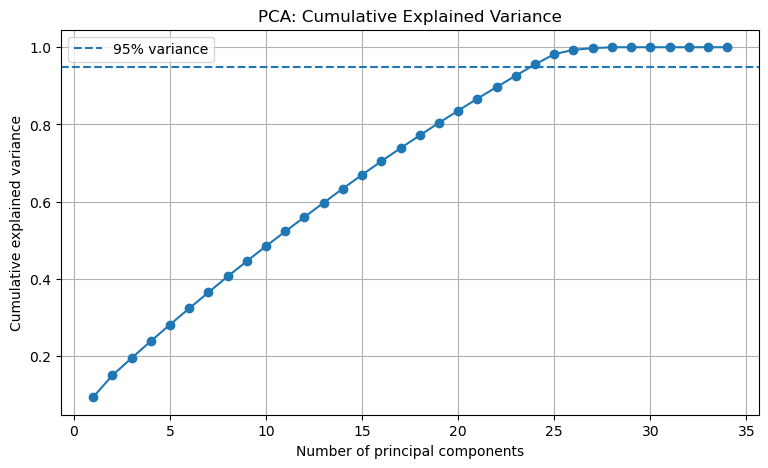

In [41]:
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: Cumulative Explained Variance")
plt.grid(True)
plt.legend()
plt.show()

In [42]:
pca_2d = PCA(n_components=2)

In [43]:
X_pca = pca_2d.fit_transform(X_scaled)

In [44]:
print("PCA shape:", X_pca.shape)

PCA shape: (1189, 2)


In [45]:
print(
    "Variance retained by 2 components:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Variance retained by 2 components: 15.02 %


In [46]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [47]:
k_values = range(2, 11)

In [48]:
inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

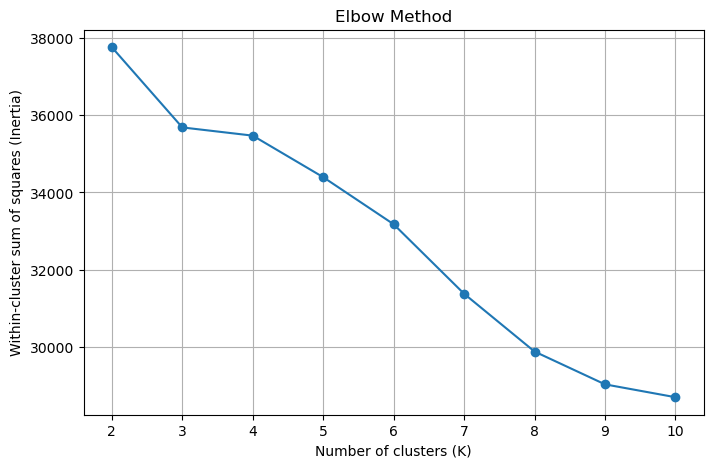

In [49]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Within-cluster sum of squares (Inertia)")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

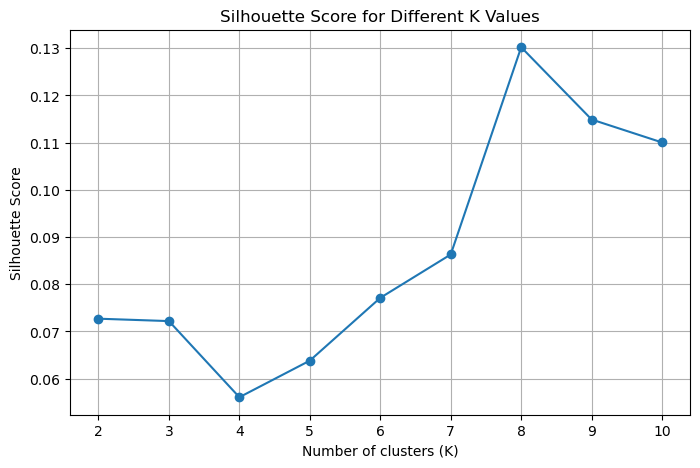

In [50]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [51]:
best_silhouette_k = list(k_values)[
    np.argmax(silhouette_scores)
]

print("Best K by Silhouette Score:", best_silhouette_k)

Best K by Silhouette Score: 8


In [53]:
final_k = best_silhouette_k

final_kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(X_scaled)

customer_segments = customer_features.copy()
customer_segments["Cluster"] = cluster_labels

print(customer_segments["Cluster"].value_counts().sort_index())


0    179
1    159
2    174
3    175
4    170
5    170
6    154
7      8
Name: Cluster, dtype: int64


In [54]:
display(customer_segments.head())

,CustomerID,TotalSpend,TotalQuantity,OrderCount,AverageOrderValue,AverageItemsInCart,AverageUnitPrice,UniqueProducts,WeekendOrderRate,Product_Chair,...,ReferralSource_Email,ReferralSource_Facebook,ReferralSource_Google,ReferralSource_Instagram,ReferralSource_Referral,CouponCode_FREESHIP,CouponCode_No Coupon,CouponCode_SAVE10,CouponCode_WINTER15,Cluster
0,C10002,1470.03,3,1,1470.03,4.0,490.01,1,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
1,C10054,153.48,2,1,153.48,7.0,76.74,1,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,4
2,C10126,1349.80,2,1,1349.80,4.0,674.90,1,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
3,C10154,1303.04,4,1,1303.04,8.0,325.76,1,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,5
4,C10211,635.90,5,1,635.90,10.0,127.18,1,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,5


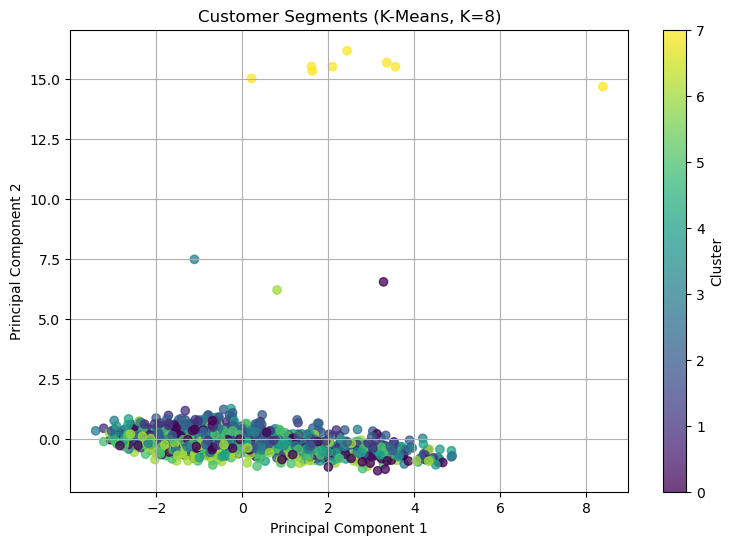

In [55]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    alpha=0.75
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"Customer Segments (K-Means, K={final_k})")
plt.colorbar(scatter, label="Cluster")
plt.grid(True)
plt.show()

In [57]:
profile_columns = [
    "TotalSpend",
    "OrderCount",
    "AverageOrderValue",
    "TotalQuantity",
    "UniqueProducts",
    "AverageUnitPrice",
    "WeekendOrderRate"
]

cluster_profiles = customer_segments.groupby("Cluster")[
    profile_columns
].mean().round(2)

display(cluster_profiles)

,TotalSpend,OrderCount,AverageOrderValue,TotalQuantity,UniqueProducts,AverageUnitPrice,WeekendOrderRate
Cluster,,,,,,,
0,1089.69,1.01,1081.71,3.00,1.0,352.04,0.35
1,1073.28,1.00,1073.28,2.95,1.0,358.56,0.34
2,1087.24,1.00,1087.24,3.15,1.0,353.28,0.29
3,1060.18,1.01,1059.63,2.80,1.0,372.49,0.30
4,1121.61,1.00,1121.61,3.09,1.0,360.55,0.31
5,985.06,1.00,985.06,2.99,1.0,329.61,0.26
6,983.12,1.01,977.68,2.66,1.0,375.53,0.24
7,1851.53,2.00,925.76,6.12,2.0,294.82,0.38


In [58]:
cluster_sizes = (
    customer_segments["Cluster"]
    .value_counts()
    .sort_index()
    .rename("CustomerCount")
)

cluster_sizes = cluster_sizes.to_frame()
cluster_sizes["Percentage"] = (
    cluster_sizes["CustomerCount"]
    / len(customer_segments) * 100
).round(2)

display(cluster_sizes)

,CustomerCount,Percentage
0,179,15.05
1,159,13.37
2,174,14.63
3,175,14.72
4,170,14.30
5,170,14.30
6,154,12.95
7,8,0.67


In [59]:
profile_columns = [
    "TotalSpend",
    "OrderCount",
    "AverageOrderValue",
    "TotalQuantity",
    "UniqueProducts",
    "AverageUnitPrice",
    "WeekendOrderRate"
]

cluster_profiles = (
    customer_segments.groupby("Cluster")[profile_columns]
    .mean()
    .round(2)
)

display(cluster_profiles)

,TotalSpend,OrderCount,AverageOrderValue,TotalQuantity,UniqueProducts,AverageUnitPrice,WeekendOrderRate
Cluster,,,,,,,
0,1089.69,1.01,1081.71,3.00,1.0,352.04,0.35
1,1073.28,1.00,1073.28,2.95,1.0,358.56,0.34
2,1087.24,1.00,1087.24,3.15,1.0,353.28,0.29
3,1060.18,1.01,1059.63,2.80,1.0,372.49,0.30
4,1121.61,1.00,1121.61,3.09,1.0,360.55,0.31
5,985.06,1.00,985.06,2.99,1.0,329.61,0.26
6,983.12,1.01,977.68,2.66,1.0,375.53,0.24
7,1851.53,2.00,925.76,6.12,2.0,294.82,0.38


In [60]:
overall_profile = customer_segments[profile_columns].mean()

cluster_comparison = (
    cluster_profiles.div(overall_profile, axis=1)
    .round(2)
)

display(cluster_comparison)

,TotalSpend,OrderCount,AverageOrderValue,TotalQuantity,UniqueProducts,AverageUnitPrice,WeekendOrderRate
Cluster,,,,,,,
0,1.02,1.00,1.02,1.01,0.99,0.99,1.17
1,1.01,0.99,1.02,0.99,0.99,1.01,1.14
2,1.02,0.99,1.03,1.06,0.99,0.99,0.97
3,1.00,1.00,1.00,0.94,0.99,1.04,1.01
4,1.05,0.99,1.06,1.04,0.99,1.01,1.04
5,0.93,0.99,0.93,1.01,0.99,0.92,0.87
6,0.92,1.00,0.93,0.89,0.99,1.05,0.80
7,1.74,1.98,0.88,2.06,1.99,0.83,1.27


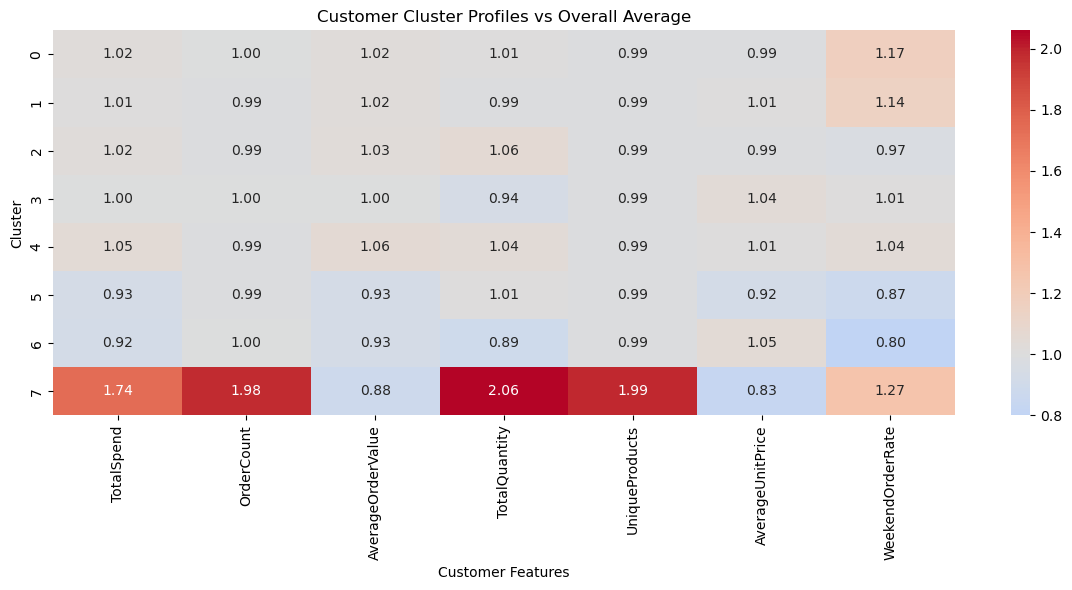

In [61]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_comparison,
    annot=True,
    cmap="coolwarm",
    center=1,
    fmt=".2f"
)

plt.title("Customer Cluster Profiles vs Overall Average")
plt.xlabel("Customer Features")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [62]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

customer_segments.to_csv(
    output_dir / "customer_segments.csv",
    index=False
)

cluster_profiles.to_csv(
    output_dir / "cluster_profiles.csv"
)

cluster_comparison.to_csv(
    output_dir / "cluster_comparison.csv"
)

print("Results saved successfully.")

Results saved successfully.
